# 08 - Eficiência computacional

Medições do modelo final (e do baseline, para comparação), cada uma isolada neste notebook (sem outros treinos
rodando em paralelo):

| Métrica | Como foi medida |
|---|---|
| Tempo total de treinamento | `time.perf_counter`, do início até a época de parada do early stopping (3 repetições) |
| Tempo de inferência (total e por amostra) | 30 repetições com 5 de aquecimento (média ± desvio), lote = teste inteiro |
| Latência individual | uma amostra por chamada, para as 1.800 amostras do teste |
| Vazão | amostras / tempo de inferência |
| Pico de memória (RAM) | `psutil` (RSS do processo), amostrado numa thread durante o treino; RSS antes/depois na inferência |
| Tamanho em disco | arquivo `.pt` |
| Complexidade | parâmetros treináveis, camadas, MACs por amostra |
| Energia e CO₂ | potência média × tempo (TDP), fator do Brasil 45,8 gCO₂/kWh |

Ao final: efeito dos hiperparâmetros no custo, contexto de implantação e tabela-resumo final.

In [1]:
import platform
import sys
from pathlib import Path

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn
import torch

from src import inference
from src.config import FATOR_EMISSAO_BR, MODELS, POTENCIA_CPU_W, TABLES, preparar, salvar_fig, salvar_tabela
from src.experiments import carregar_log, estudos, resumir
from src.models import macs_por_amostra, n_parametros
from src.profiling import MonitorRSS, energia_co2, medir_inferencia, medir_latencia_individual, tamanho_kb
from src.train import executar

torch.set_num_threads(1)

## 1. Ambiente computacional

In [2]:
def nome_cpu():
    try:
        import winreg
        k = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
        return winreg.QueryValueEx(k, "ProcessorNameString")[0].strip()
    except Exception:
        return platform.processor()

ambiente = pd.Series({
    "Sistema operacional": f"{platform.system()} {platform.release()} ({platform.version()})",
    "Processador": f"{nome_cpu()} (TDP {POTENCIA_CPU_W:.0f} W)",
    "Núcleos físicos / lógicos": f"{psutil.cpu_count(logical=False)} / {psutil.cpu_count()}",
    "Memória RAM (GB)": f"{psutil.virtual_memory().total / 2**30:.1f}",
    "GPU": "não (PyTorch em CPU; torch.cuda.is_available() = False)",
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "Threads do PyTorch nas medições (torch.get_num_threads())": torch.get_num_threads(),
}, name="valor")
salvar_tabela(ambiente.to_frame(), "ambiente", index=True)
ambiente.to_frame()

,valor
Sistema operacional,Windows 10 (10.0.19045)
Processador,AMD Ryzen 5 5600X 6-Core Processor (TDP 65 W)
Núcleos físicos / lógicos,6 / 12
Memória RAM (GB),15.9
GPU,não (PyTorch em CPU; torch.cuda.is_available()...
Python,3.13.3
PyTorch,2.14.0+cpu
NumPy,2.5.3
pandas,2.3.3
scikit-learn,1.7.2


Todos os treinos do trabalho usam 1 thread (`torch.set_num_threads(1)`), o que torna os resultados reprodutíveis
bit a bit entre execuções e permitiu rodar o estudo de hiperparâmetros com 6 processos em paralelo (um por núcleo
físico). O efeito do número de threads na inferência é medido na Seção 4.

## 2. Tempo e memória de treinamento

Retreina-se a configuração final e o baseline com a mesma semente do modelo salvo. Antes de medir, confere-se que
o retreino reproduz exatamente os pesos do arquivo (reprodutibilidade).

In [3]:
linhas = []
for p in ("regressao", "classificacao"):
    dados = preparar(p)
    for nome, arq in (("Baseline", "baseline"), ("Final", "modelo")):
        modelo_arq, ck = inference.carregar(MODELS / f"{arq}_{p}.pt")
        cfg, seed = ck["hiperparametros"], ck["seed"]
        tempos, picos, acresc = [], [], []
        for rep in range(3):
            with MonitorRSS() as mon:
                r, h, m = executar(cfg, dados, seed, retornar_modelo=True)
            tempos.append(r["tempo_treino_s"]); picos.append(mon.pico_mb); acresc.append(mon.acrescimo_mb)
        iguais = all(torch.equal(a, b) for a, b in zip(m.state_dict().values(), modelo_arq.state_dict().values()))
        kwh, g = energia_co2(np.mean(tempos))
        linhas.append({"problema": p, "modelo": nome, "épocas executadas": r["epocas_executadas"],
                       "melhor época": r["melhor_epoca"], "tempo treino (s)": np.mean(tempos),
                       "desvio (s)": np.std(tempos), "tempo/época (ms)": 1000 * np.mean(tempos) / r["epocas_executadas"],
                       "pico RSS treino (MB)": max(picos), "acréscimo RSS treino (MB)": max(acresc),
                       "energia treino (Wh)": 1000 * kwh, "CO2 treino (mg)": 1000 * g,
                       "pesos idênticos ao arquivo": iguais})
treino = pd.DataFrame(linhas)
salvar_tabela(treino, "eficiencia_treino")
treino.round(4)

,problema,modelo,épocas executadas,melhor época,tempo treino (s),desvio (s),tempo/época (ms),pico RSS treino (MB),acréscimo RSS treino (MB),energia treino (Wh),CO2 treino (mg),pesos idênticos ao arquivo
0,regressao,Baseline,25,5,2.9042,0.0330,116.1674,420.9492,73.0508,0.0524,2.4016,True
1,regressao,Final,141,121,37.0171,0.0933,262.5327,421.7539,0.7578,0.6684,30.6111,True
2,classificacao,Baseline,26,6,3.1517,0.0098,121.2180,425.2578,1.2266,0.0569,2.6063,True
3,classificacao,Final,23,3,4.3533,0.0103,189.2718,425.3867,0.2344,0.0786,3.5999,True


## 3. Inferência: lote × uma amostra por vez

In [4]:
linhas = []
for p in ("regressao", "classificacao"):
    dados = preparar(p)
    X = torch.tensor(dados.X_te)
    for nome, arq in (("Baseline", "baseline"), ("Final", "modelo")):
        m, ck = inference.carregar(MODELS / f"{arq}_{p}.pt")
        lote = medir_inferencia(m, X)
        indiv = medir_latencia_individual(m, X)
        kwh_l, g_l = energia_co2(lote["tempo_medio_s"])
        kwh_i, g_i = energia_co2(indiv["tempo_total_s"])
        hidden = ck["config"]["hidden"]
        linhas.append({
            "problema": p, "modelo": nome, "camadas ocultas": str(hidden),
            "parâmetros": n_parametros(m), "MACs/amostra": macs_por_amostra(len(ck["features"]), hidden),
            "disco (KB)": tamanho_kb(MODELS / f"{arq}_{p}.pt"),
            "lote: tempo total (ms)": 1000 * lote["tempo_medio_s"], "lote: desvio (ms)": 1000 * lote["tempo_desvio_s"],
            "lote: por amostra (µs)": 1000 * lote["tempo_por_amostra_ms"], "lote: vazão (amostras/s)": lote["vazao_amostras_s"],
            "individual: latência (ms)": indiv["latencia_media_ms"], "individual: p95 (ms)": indiv["latencia_p95_ms"],
            "individual: vazão (amostras/s)": indiv["vazao_amostras_s"],
            "RSS inferência (MB)": lote["rss_mb"], "Δ RSS inferência (KB)": lote["delta_memoria_kb"],
            "energia inf. lote (µWh)": 1e9 * kwh_l, "CO2 inf. lote (µg)": 1e6 * g_l,
            "energia inf. individual (µWh)": 1e9 * kwh_i,
        })
inf = pd.DataFrame(linhas)
salvar_tabela(inf, "eficiencia_inferencia")
inf.T

,0,1,2,3
problema,regressao,regressao,classificacao,classificacao
modelo,Baseline,Final,Baseline,Final
camadas ocultas,"[32, 32]","[32, 32]","[32, 32]",[8]
parâmetros,2081,2081,2081,257
MACs/amostra,2016,2016,2016,248
disco (KB),13.913086,16.135742,14.092773,6.360352
lote: tempo total (ms),0.145113,0.233657,0.145083,0.180287
lote: desvio (ms),0.005483,0.004825,0.005882,0.002345
lote: por amostra (µs),0.080619,0.129809,0.080602,0.100159
lote: vazão (amostras/s),12404097.944774,7703610.711093,12406662.8294,9984099.397238


Em lote, uma única chamada multiplica uma matriz 1.800 × 30 pelos pesos: o custo fixo de cada chamada (despacho
do Python para o C++, alocação dos tensores de saída, verificação de formas) é pago uma vez e dividido por 1.800
amostras, e as operações usam rotinas vetorizadas (BLAS). Uma amostra por vez paga esse custo fixo 1.800 vezes;
como a rede é pequena (poucos milhares de MACs), o custo fixo domina e a vazão cai em mais de uma ordem de grandeza.

## 4. Efeito do número de threads na inferência em lote

In [5]:
dados = preparar("classificacao")
X = torch.tensor(dados.X_te)
m, ck = inference.carregar(MODELS / "modelo_classificacao.pt")
linhas = []
for n in (1, 2, 4, 6):
    torch.set_num_threads(n)
    r = medir_inferencia(m, X)
    linhas.append({"threads": n, "tempo lote (ms)": 1000 * r["tempo_medio_s"], "desvio (ms)": 1000 * r["tempo_desvio_s"],
                   "vazão (amostras/s)": r["vazao_amostras_s"]})
torch.set_num_threads(1)
threads = pd.DataFrame(linhas)
salvar_tabela(threads, "eficiencia_threads")
threads.round(4)

,threads,tempo lote (ms),desvio (ms),vazão (amostras/s)
0,1,0.1807,0.0058,9.963835e+06
1,2,0.1227,0.0064,1.467152e+07
2,4,0.1797,0.0213,1.001577e+07
3,6,0.1449,0.0032,1.242207e+07


## 5. Energia e CO₂

Método: energia = potência média × tempo, com a potência igual ao TDP do processador (65 W), e CO₂ = energia ×
45,8 gCO₂/kWh (fator de emissão do Brasil apresentado em aula, baseado no Sistema Interligado Nacional).
Como o processo usa 1 thread de 12, o TDP inteiro é um **limite superior**; uma estimativa proporcional a 1 núcleo
(65 W / 6 ≈ 10,8 W) daria valores ~6 vezes menores. A biblioteca `codecarbon` não foi usada: em Windows com
processador AMD ela não tem acesso a contadores de energia (RAPL) e também recorre a uma estimativa pelo TDP.

In [6]:
energia = treino[["problema", "modelo", "tempo treino (s)", "energia treino (Wh)", "CO2 treino (mg)"]].merge(
    inf[["problema", "modelo", "energia inf. lote (µWh)", "CO2 inf. lote (µg)"]], on=["problema", "modelo"])
energia["energia treino, 1 núcleo (Wh)"] = energia["energia treino (Wh)"] / 6
energia["inferências por Wh (lote)"] = 1800 / (energia["energia inf. lote (µWh)"] * 1e-6)
salvar_tabela(energia, "energia_co2")
energia.round(5)

,problema,modelo,tempo treino (s),energia treino (Wh),CO2 treino (mg),energia inf. lote (µWh),CO2 inf. lote (µg),"energia treino, 1 núcleo (Wh)",inferências por Wh (lote)
0,regressao,Baseline,2.90419,0.05244,2.40160,2.62010,0.12000,0.00874,6.869962e+08
1,regressao,Final,37.01711,0.66836,30.61109,4.21880,0.19322,0.11139,4.266615e+08
2,classificacao,Baseline,3.15167,0.05691,2.60625,2.61956,0.11998,0.00948,6.871382e+08
3,classificacao,Final,4.35325,0.07860,3.59990,3.25518,0.14909,0.01310,5.529655e+08


## 6. Efeito dos hiperparâmetros no custo

A partir do estudo de hiperparâmetros (média de 5 sementes). Os tempos do estudo foram medidos com 6 treinos
simultâneos (1 por núcleo), então servem para comparar configurações entre si, e não como valores absolutos.
O tamanho em disco de cada arquitetura foi medido salvando o `state_dict` de uma rede recém-criada.

In [7]:
import os, tempfile
from src.models import MLP

log = carregar_log()
def disco_kb(neur, cam):
    with tempfile.TemporaryDirectory() as d:
        c = os.path.join(d, "m.pt")
        torch.save(MLP(30, 1, tuple([neur] * cam)).state_dict(), c)
        return os.path.getsize(c) / 1024

linhas = []
for hp in ("neuronios", "camadas", "batch"):
    tab = resumir("classificacao", estudos("classificacao")[hp], log)
    tab_r = resumir("regressao", estudos("regressao")[hp], log)
    for (_, r), (_, rr) in zip(tab.iterrows(), tab_r.iterrows()):
        neur = int(r["valor"]) if hp == "neuronios" else 32
        cam = int(r["valor"]) if hp == "camadas" else 2
        linhas.append({"hiperparâmetro": hp, "valor": r["valor"], "parâmetros": r["n_parametros"],
                       "MACs/amostra": macs_por_amostra(30, [neur] * cam), "disco state_dict (KB)": disco_kb(neur, cam),
                       "tempo/época clf (ms)": 1000 * r["tempo_por_epoca_s_media"],
                       "épocas clf": r["epocas_executadas_media"], "tempo total clf (s)": r["tempo_treino_s_media"],
                       "tempo/época reg (ms)": 1000 * rr["tempo_por_epoca_s_media"],
                       "épocas reg": rr["epocas_executadas_media"], "tempo total reg (s)": rr["tempo_treino_s_media"]})
custo = pd.DataFrame(linhas)
salvar_tabela(custo, "custo_hiperparametros")
custo.round(2)

,hiperparâmetro,valor,parâmetros,MACs/amostra,disco state_dict (KB),tempo/época clf (ms),épocas clf,tempo total clf (s),tempo/época reg (ms),épocas reg,tempo total reg (s)
0,neuronios,2,71,66,2.89,133.00,100.6,13.34,120.54,78.0,9.33
1,neuronios,4,149,140,3.14,131.84,55.0,7.21,119.44,55.8,6.66
2,neuronios,8,329,312,3.76,133.32,30.0,4.00,119.36,30.8,3.68
3,neuronios,16,785,752,5.45,132.97,26.6,3.54,121.66,31.4,3.81
4,neuronios,32,2081,2016,10.51,131.14,26.0,3.41,124.08,24.4,3.02
5,neuronios,64,6209,6080,26.64,138.41,24.0,3.32,126.91,23.4,2.97
6,neuronios,128,20609,20352,82.89,148.29,24.0,3.56,139.50,22.6,3.15
7,camadas,1,1025,992,6.03,107.34,28.8,3.09,97.16,25.6,2.49
8,camadas,2,2081,2016,10.51,131.14,26.0,3.41,124.08,24.4,3.02
9,camadas,3,3137,3040,15.06,157.34,25.2,3.97,149.06,23.6,3.51


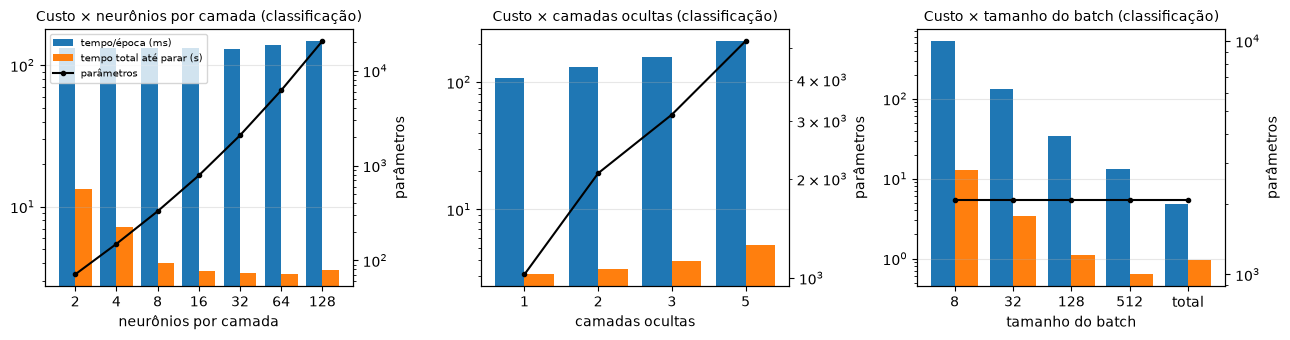

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, hp, xl in zip(axes, ("neuronios", "camadas", "batch"), ("neurônios por camada", "camadas ocultas", "tamanho do batch")):
    t = custo[custo["hiperparâmetro"] == hp]
    x = np.arange(len(t))
    ax.bar(x - 0.2, t["tempo/época clf (ms)"], 0.4, label="tempo/época (ms)", color="#1f77b4")
    ax.bar(x + 0.2, t["tempo total clf (s)"], 0.4, label="tempo total até parar (s)", color="#ff7f0e")
    ax.set_xticks(x, t["valor"]); ax.set_xlabel(xl); ax.set_yscale("log")
    ax2 = ax.twinx(); ax2.plot(x, t["parâmetros"], "k.-", label="parâmetros"); ax2.set_yscale("log")
    ax2.set_ylabel("parâmetros")
    ax.set_title(f"Custo × {xl} (classificação)", fontsize=10); ax.grid(alpha=0.3, axis="y")
    if hp == "neuronios":
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
fig.tight_layout()
salvar_fig("custo_hiperparametros")
plt.show()

## 7. Tabela-resumo final

In [9]:
met_reg = pd.read_csv(TABLES / "metricas_regressao.csv")
met_clf = pd.read_csv(TABLES / "metricas_classificacao.csv")
cv = {p: pd.read_csv(TABLES / f"kfold_{p}.csv") for p in ("regressao", "classificacao")}
linhas = []
for p, met, tab in (("regressao", "RMSE", met_reg), ("classificacao", "F1", met_clf)):
    for nome, arq in (("Baseline", "baseline"), ("Final", "modelo")):
        m, ck = inference.carregar(MODELS / f"{arq}_{p}.pt")
        hp = ck["hiperparametros"]
        t = tab[tab["modelo"] == f"MLP {nome}"].set_index("conjunto")
        e_t = treino.query("problema == @p and modelo == @nome").iloc[0]
        e_i = inf.query("problema == @p and modelo == @nome").iloc[0]
        linha = {"problema": p, "modelo": nome,
                 "arquitetura": f"{hp['camadas']}×{hp['neuronios']} {hp['ativacao']}",
                 "otimizador / lr / batch": f"{hp['otimizador']} / {hp['lr']:g} / {hp['batch']}",
                 "weight decay / dropout": f"{hp['weight_decay']:g} / {hp['dropout']:g}",
                 "perda": hp["perda"] if p == "regressao" else f"BCE (pos_weight={hp['pos_weight']:g})",
                 f"{met} treino": t.loc["treino", met], f"{met} validação": t.loc["validação", met],
                 f"{met} teste": t.loc["teste", met], "gap (treino - teste)": t.loc["treino", met] - t.loc["teste", met]}
        if p == "regressao":
            linha.update({"MAE teste": t.loc["teste", "MAE"], "R2 teste": t.loc["teste", "R2"]})
        else:
            linha.update({"limiar": ck["limiar"], "Recall teste": t.loc["teste", "Recall"], "PR-AUC teste": t.loc["teste", "PR-AUC"]})
        if nome == "Final":
            linha[f"{met} K-fold"] = f"{cv[p][met].mean():.4f} ± {cv[p][met].std():.4f}"
        linha.update({"parâmetros": e_i["parâmetros"], "disco (KB)": e_i["disco (KB)"],
                      "treino (s)": e_t["tempo treino (s)"], "inferência/amostra lote (µs)": e_i["lote: por amostra (µs)"],
                      "latência individual (ms)": e_i["individual: latência (ms)"],
                      "pico RSS treino (MB)": e_t["pico RSS treino (MB)"], "CO2 treino (mg)": e_t["CO2 treino (mg)"]})
        linhas.append(linha)
resumo = pd.DataFrame(linhas)
salvar_tabela(resumo, "resumo_final")
resumo.T

,0,1,2,3
problema,regressao,regressao,classificacao,classificacao
modelo,Baseline,Final,Baseline,Final
arquitetura,2×32 ReLU,2×32 Sigmoid,2×32 ReLU,1×8 Tanh
otimizador / lr / batch,Adam / 0.001 / 32,AdamW / 0.00016 / 16,Adam / 0.001 / 32,RMSprop / 0.00162 / 16
weight decay / dropout,0 / 0,0.0001 / 0.1,0 / 0,0.0001 / 0.1
perda,MSE,Huber,BCE (pos_weight=1),BCE (pos_weight=1.25)
RMSE treino,11.565387,11.769243,NaN,NaN
RMSE validação,11.723082,11.672724,NaN,NaN
RMSE teste,12.328414,12.16409,NaN,NaN
gap (treino - teste),-0.763027,-0.394847,0.042018,0.019523
